# 04_eda: exploratory analysis
Aggregates only: no raw ticket rows are printed. Input: data/processed/itsm_clean.pkl (from 03_cleaning). The findings here set the modelling window and the Track 1 split used in 05_split_features, and the Track 2 series in 07_track2_volume.

## 1. Setup and load the clean data

In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter, MaxNLocator
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
sys.path.append("../src")

# axis labels like 2k, 2.5k
thousands = FuncFormatter(lambda v, _: (f"{v / 1000:.1f}".rstrip("0").rstrip(".") + "k") if v >= 1000 else f"{v:.0f}")

df = pd.read_pickle("../data/processed/itsm_clean.pkl")
print(df.shape)

(46606, 26)


<details>
<summary><b>Code notes, line by line</b></summary>

- `import sys, os, numpy, pandas, matplotlib, seaborn` : Paths, arrays, data frames and plotting (seaborn draws the heatmaps and box plots).
- `from matplotlib.ticker import FuncFormatter, MaxNLocator` : Tools to format axis labels and limit the number of ticks.
- `from sklearn ... TfidfVectorizer, cosine_similarity` : Used in section 14 to compare asset labels.
- `thousands = FuncFormatter(lambda v, _: ...)` : Axis formatter that writes 2000 as 2k and 2500 as 2.5k.
- `df = pd.read_pickle(...); print(df.shape)` : Loads the clean checkpoint from 03 and shows its size.

</details>

## 2. Columns added and removed during cleaning

In [2]:
raw_cols = pd.read_csv("../data/raw/itsm_raw.csv", nrows=0).columns
print("Table 2. Columns added and removed during cleaning")
print("Added  :", sorted(set(df.columns) - set(raw_cols)))
print("Removed:", sorted(set(raw_cols) - set(df.columns)))

Table 2. Columns added and removed during cleaning
Added  : ['Elapsed_hrs', 'Has_Related_Change', 'Has_Reopen_Time']
Removed: ['Alert_Status', 'number_cnt']


<details>
<summary><b>Code notes, line by line</b></summary>

- `raw_cols = pd.read_csv(..., nrows=0).columns` : Reads only the header of the raw snapshot.
- `sorted(set(df.columns) - set(raw_cols))` : Columns created during cleaning (the flags and Elapsed_hrs).
- `sorted(set(raw_cols) - set(df.columns))` : Columns dropped during cleaning.

</details>

**Result.** Cleaning added three columns (the two presence flags and Elapsed_hrs) and removed two (Alert_Status and number_cnt) (Table 2).

## 3. Target balance: Priority and the High (P1+P2) share

In [3]:
lab = df[df["Priority"].notna()]
print("Table 3. Tickets per priority | labelled tickets:", len(lab))
print(lab["Priority"].astype(int).value_counts().sort_index())
print("High (P1+P2) share:", round(lab["Priority"].isin([1, 2]).mean() * 100, 2), "%")

Table 3. Tickets per priority | labelled tickets: 45226
Priority
1        3
2      697
3     5323
4    22717
5    16486
Name: count, dtype: int64
High (P1+P2) share: 1.55 %


<details>
<summary><b>Code notes, line by line</b></summary>

- `lab = df[df["Priority"].notna()]` : Tickets with a priority label.
- `lab["Priority"].astype(int).value_counts().sort_index()` : Tickets per priority, P1 to P5.
- `lab["Priority"].isin([1, 2]).mean() * 100` : Share of High (P1 or P2) tickets: the Track 1 class balance.

</details>

**Result.** 45,226 tickets have a priority: 3 P1, 697 P2, 5,323 P3, 22,717 P4 and 16,486 P5, so High (P1 + P2) is only 1.55% (Table 3). This imbalance is why accuracy is not used to judge Track 1.

## 4. Univariate distributions

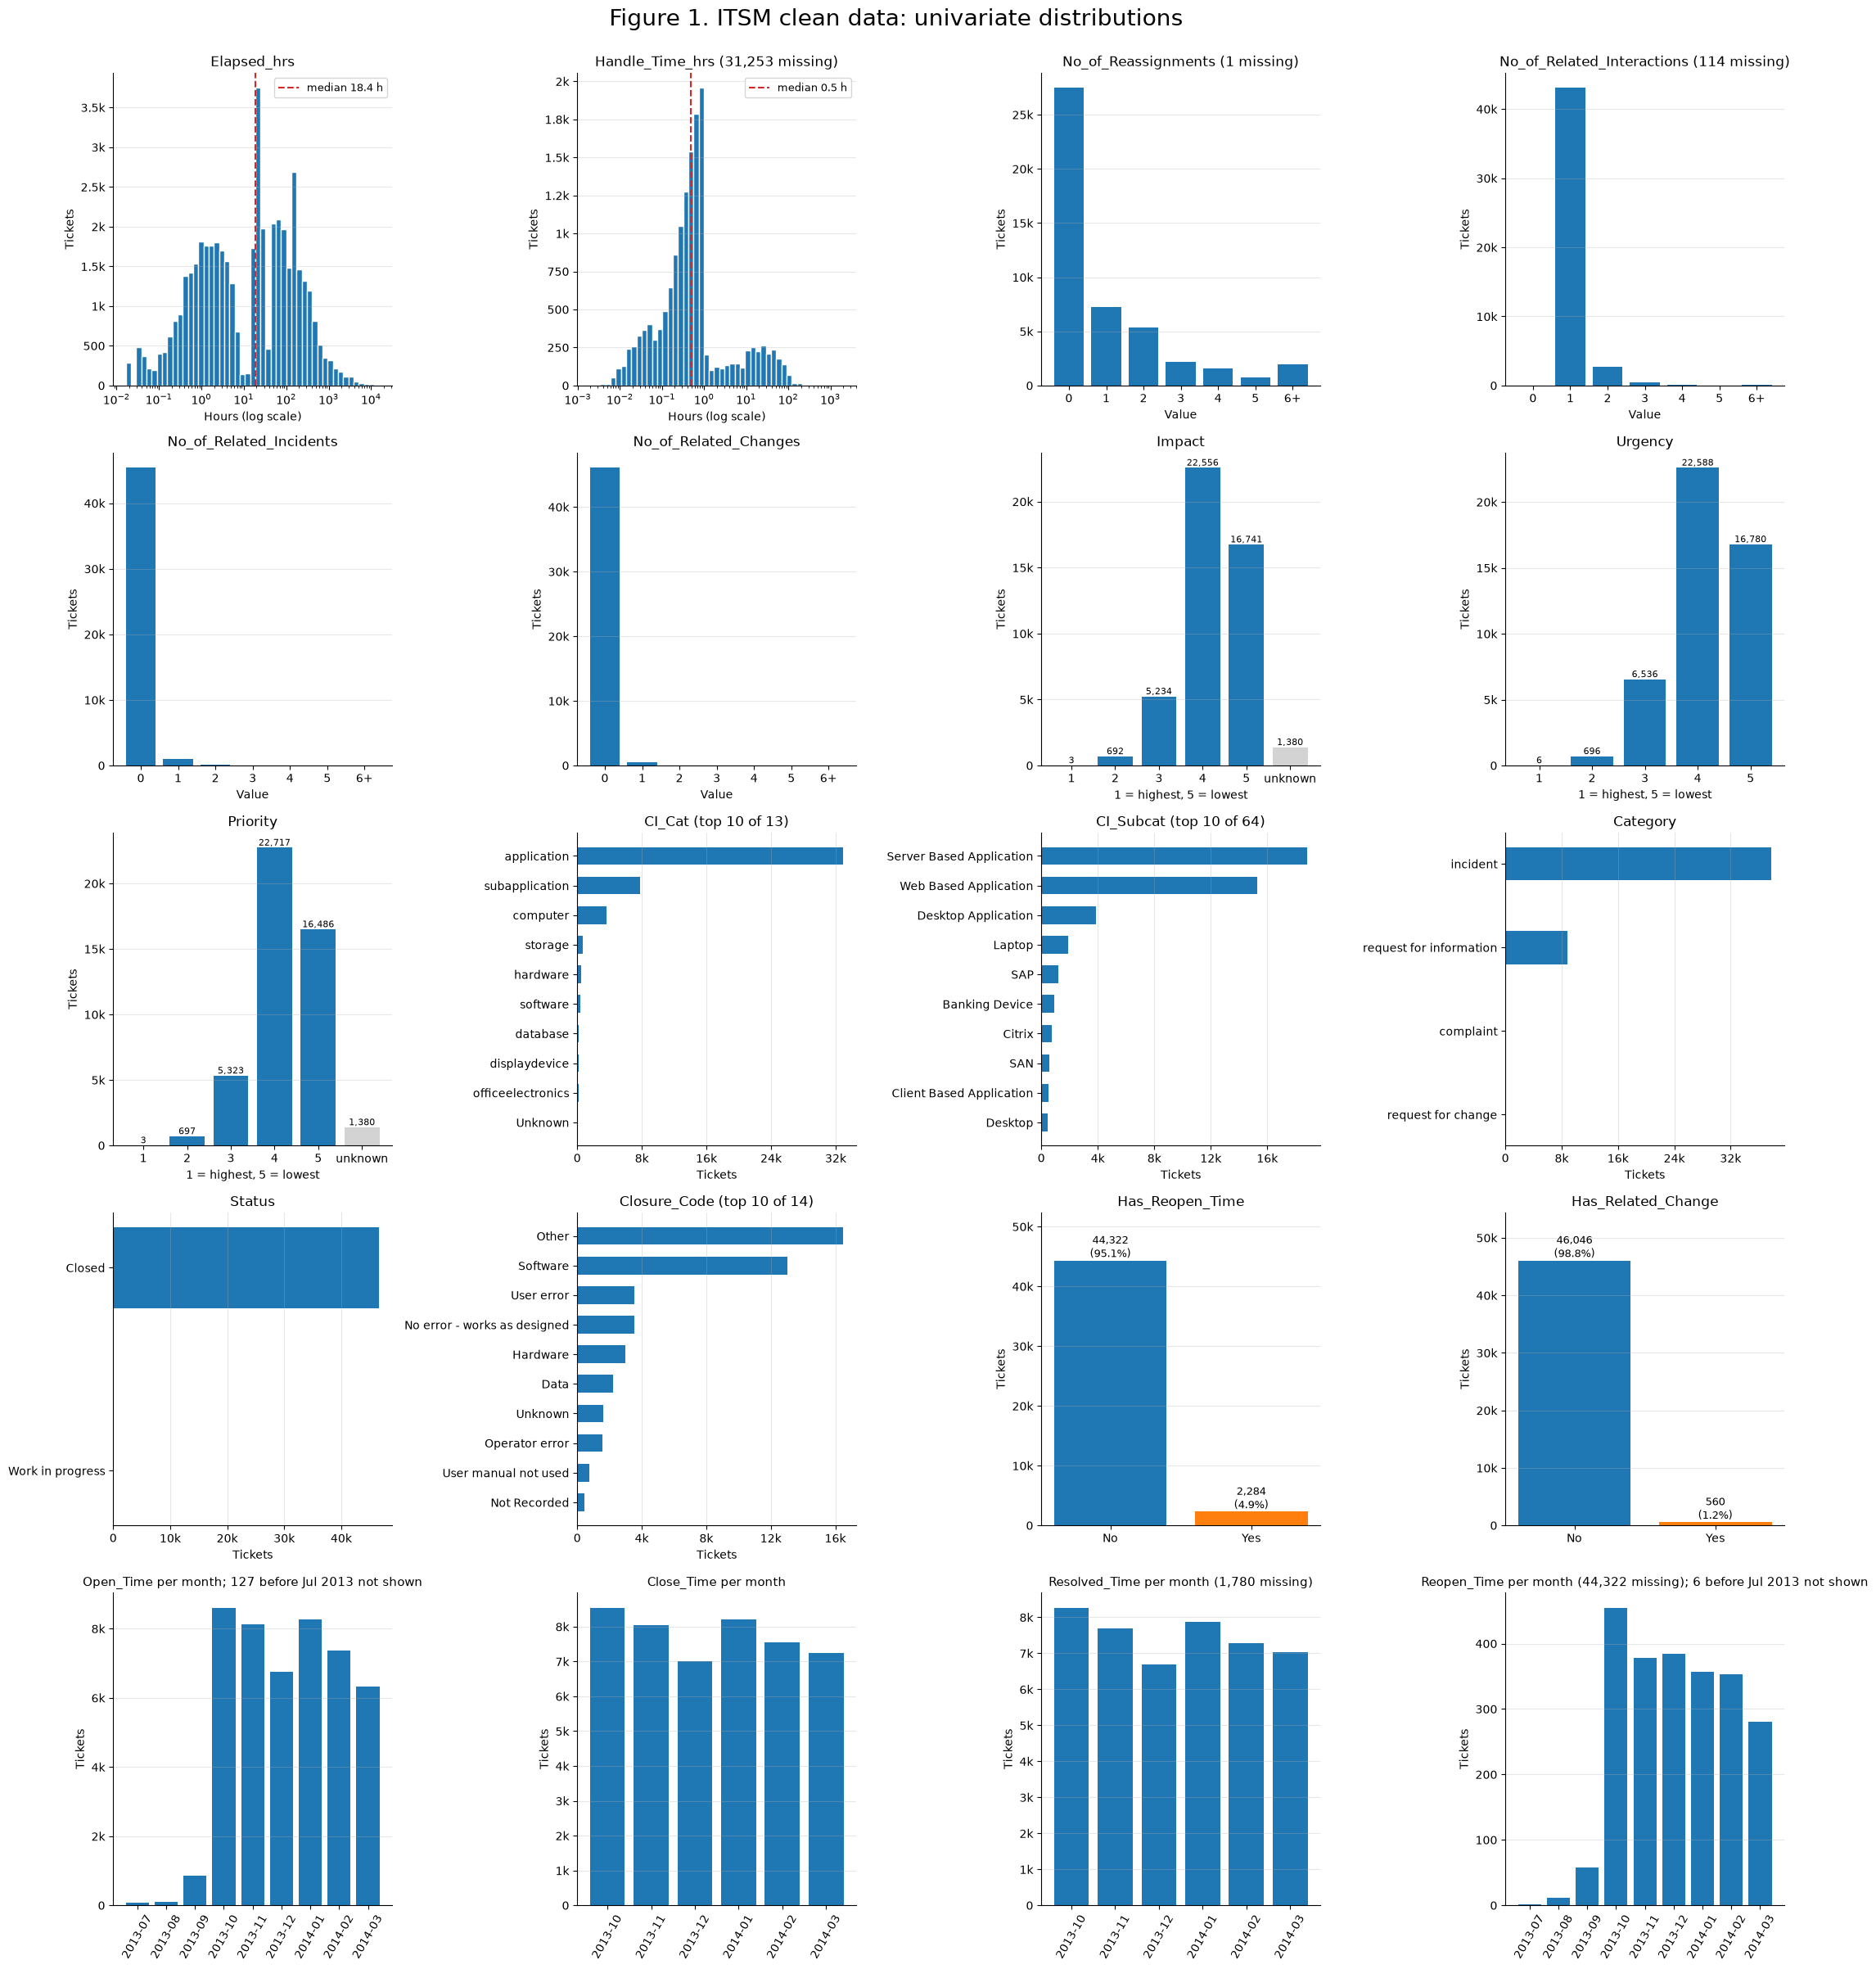

In [4]:
# Column groups in the clean file (identifiers such as Incident_ID, CI_Name and WBS are not plotted)
continuous_cols = ["Elapsed_hrs", "Handle_Time_hrs"]                       # heavily right-skewed: log scale
count_cols = ["No_of_Reassignments", "No_of_Related_Interactions",
              "No_of_Related_Incidents", "No_of_Related_Changes"]           # small whole numbers: bars
ordinal_cols = ["Impact", "Urgency", "Priority"]                           # 1 (highest) to 5 (lowest)
category_cols = ["CI_Cat", "CI_Subcat", "Category", "Status", "Closure_Code"]
flag_cols = ["Has_Reopen_Time", "Has_Related_Change"]
datetime_cols = ["Open_Time", "Close_Time", "Resolved_Time", "Reopen_Time"]

panels = ([("continuous", c) for c in continuous_cols] + [("count", c) for c in count_cols]
          + [("ordinal", c) for c in ordinal_cols] + [("category", c) for c in category_cols]
          + [("flag", c) for c in flag_cols] + [("datetime", c) for c in datetime_cols])

fig, axes = plt.subplots(5, 4, figsize=(22, 24))
axes = axes.flatten()
bar = "tab:blue"

for ax, (kind, col) in zip(axes, panels):
    s = df[col]
    missing = int(s.isna().sum())
    note = f" ({missing:,} missing)" if missing else ""

    if kind == "continuous":
        x = s.dropna()
        x = x[x > 0]
        bins = np.logspace(np.log10(x.min()), np.log10(x.max()), 50)
        ax.hist(x, bins=bins, color=bar, edgecolor="white")
        ax.set_xscale("log")
        ax.axvline(x.median(), color="tab:red", linestyle="--", label=f"median {x.median():.1f} h")
        ax.legend(fontsize=9)
        ax.set_xlabel("Hours (log scale)")
        ax.set_ylabel("Tickets")
        ax.set_title(f"{col}{note}")

    elif kind == "count":
        v = s.dropna().astype(int).clip(upper=6)
        counts = v.value_counts().reindex(range(7), fill_value=0)
        ax.bar([str(k) if k < 6 else "6+" for k in counts.index], counts.values, color=bar)
        ax.set_xlabel("Value")
        ax.set_ylabel("Tickets")
        ax.set_title(f"{col}{note}")

    elif kind == "ordinal":
        counts = s.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
        labels = [str(k) for k in counts.index]
        values = list(counts.values)
        if missing:
            labels.append("unknown"); values.append(missing)
        ax.bar(labels, values, color=[bar] * 5 + ["lightgrey"] * (len(values) - 5))
        for k, v in enumerate(values):
            ax.text(k, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
        ax.set_xlabel("1 = highest, 5 = lowest")
        ax.set_ylabel("Tickets")
        ax.set_title(col)

    elif kind == "category":
        top = s.value_counts().head(10).iloc[::-1]
        ax.barh(top.index.astype(str), top.values, color=bar, height=0.6 if len(top) > 4 else 0.4)
        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.set_xlabel("Tickets")
        more = s.nunique() - len(top)
        ax.set_title(f"{col}" + (f" (top 10 of {s.nunique()})" if more > 0 else ""))

    elif kind == "flag":
        counts = s.value_counts().reindex([0, 1], fill_value=0)
        ax.bar(["No", "Yes"], counts.values, color=[bar, "tab:orange"])
        for k, v in enumerate(counts.values):
            ax.text(k, v, f"{v:,}\n({v / len(s) * 100:.1f}%)", ha="center", va="bottom", fontsize=9)
        ax.set_ylim(0, counts.max() * 1.18)
        ax.set_ylabel("Tickets")
        ax.set_title(col)

    else:  # datetime: tickets per month, from July 2013 (earlier months hold only a few backlog tickets)
        monthly = s.dropna().dt.to_period("M").value_counts().sort_index()
        early = int(monthly[monthly.index < pd.Period("2013-07", "M")].sum())
        monthly = monthly[monthly.index >= pd.Period("2013-07", "M")]
        ax.bar(monthly.index.strftime("%Y-%m"), monthly.values, color=bar)
        ax.tick_params(axis="x", rotation=60)
        ax.set_ylabel("Tickets")
        extra = f"; {early:,} before Jul 2013 not shown" if early else ""
        ax.set_title(f"{col} per month{note}{extra}", fontsize=10.5)

    (ax.xaxis if kind == "category" else ax.yaxis).set_major_formatter(thousands)
    ax.grid(axis="y" if kind != "category" else "x", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[len(panels):]:
    ax.axis("off")

fig.suptitle("Figure 1. ITSM clean data: univariate distributions", fontsize=20, y=1.0)
fig.tight_layout()
plt.show()

<details>
<summary><b>Code notes, line by line</b></summary>

- `continuous_cols / count_cols / ordinal_cols / category_cols / flag_cols / datetime_cols` : Groups the columns by the kind of chart that suits them.
- `panels = [("continuous", c) for c in ...] + ...` : One (kind, column) pair per chart, 20 in all.
- `fig, axes = plt.subplots(5, 4, figsize=(22, 24)); axes = axes.flatten()` : A 5 x 4 grid of charts, flattened to a simple list.
- `for ax, (kind, col) in zip(axes, panels):` : Draws one chart per column.
- `missing = int(s.isna().sum()); note = ...` : Adds the number of missing values to the title.
- `kind == "continuous": np.logspace(...); ax.set_xscale("log")` : Histogram with log-spaced bins for the skewed hour columns; zeros dropped (log of 0 is undefined); the red dashed line marks the median.
- `kind == "count": .clip(upper=6) ... "6+"` : Bars for 0 to 5 and a pooled 6+ bar for the small whole-number counts.
- `kind == "ordinal": reindex([1, 2, 3, 4, 5]) ... "unknown"` : Bars for scale values 1 to 5 plus a grey bar for missing values, each labelled with its count.
- `kind == "category": value_counts().head(10).iloc[::-1]; barh` : Horizontal bars of the 10 most common categories, largest at the top.
- `kind == "flag": reindex([0, 1]) ... f"{v:,}\n({...}%)"` : No/Yes bars with counts and percentages.
- `else (datetime): dt.to_period("M").value_counts() ... >= 2013-07` : Tickets per month from July 2013; the few earlier tickets are counted in the title instead.
- `set_major_formatter(thousands); ax.grid(...); ax.spines[...]` : Readable 'k' labels, a light grid and no top or right frame lines.
- `for ax in axes[len(panels):]: ax.axis("off")` : Hides unused grid cells.
- `fig.suptitle(...); fig.tight_layout(); plt.show()` : Title, spacing and display.

</details>

**Why this analysis:** to see each column's shape, range and missing values before modelling, and decide how each one can be used. Scope: whole clean file (46,606 tickets); the models use the 1 October 2013 to 16 March 2014 window, so some rates differ slightly. Each finding names the panel of Figure 1 it is read from.

| Finding | Evidence | Action taken in the project |
|---|---|---|
| Elapsed_hrs and Handle_Time_hrs are extremely skewed (minutes to thousands of hours; medians 18.4 h and 0.5 h) and are only known after a ticket is handled | Figure 1, Elapsed_hrs and Handle_Time_hrs panels (log scale, red median line) | Excluded from all features as post-event (`05_split_features`); no capping or transform needed (section 5) |
| Handle_Time_hrs has 31,253 unreadable values | Figure 1, Handle_Time_hrs panel title (missing count) | Kept as missing after testing whether they could be recovered; not used (`03_cleaning`, `data_issues_log.md`) |
| Only 3 tickets are P1 and 697 are P2 (1.55% High); 1,380 have no priority | Figure 1, Priority panel ("unknown" bar); Table 3 | P1 and P2 merged into "High"; unlabelled tickets excluded from Track 1; balanced class weights; recall, precision and average precision used instead of accuracy (`06_track1_models`) |
| About 59% of tickets are never reassigned | Figure 1, No_of_Reassignments panel (bar at 0) | "Reassigned at least once" (about 41%) used as the Track 3 target (`09_track3_triage`) |
| Linked changes are rare (560 tickets, 1.2%) | Figure 1, Has_Related_Change panel ("Yes" bar) | Track 4 treated as a rare-event problem; tested with and without the five largest changes (`08_track4_rfc`) |
| CI_Subcat has 65 values with a long tail; Category has two values with fewer than 15 tickets | Figure 1, CI_Subcat panel (top 10 of 65) and Category panel | Rare values (fewer than 30 training rows) pooled into "infrequent" by the encoder (all classifiers) |
| Status is almost always Closed | Figure 1, Status panel | Excluded from features (`05_split_features`) |
| Opened tickets are near zero before October 2013; closed tickets cover only October to March | Figure 1, Open_Time and Close_Time panels; Table 8 | Extract identified as cut by close date; modelling window set to 1 October to 16 March, 167 days (`04_eda`) |

## 5. Outlier check: the IQR rule
Values above Q3 + 1.5 x IQR, for the count columns and elapsed time.

In [5]:
rows = []
for c in ["No_of_Reassignments", "No_of_Related_Interactions", "No_of_Related_Incidents", "Elapsed_hrs"]:
    s = df[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    fence = q3 + 1.5 * (q3 - q1)
    rows.append({"Column": c, "Q1": q1, "Median": s.median(), "Q3": q3, "Upper fence": fence, "Max": s.max(),
                 "Above fence": int((s > fence).sum()), "Above fence %": round((s > fence).mean() * 100, 1)})
print("Table 5. Values above the IQR upper fence (Q3 + 1.5 x IQR)")
display(pd.DataFrame(rows).set_index("Column").round(1))

Table 5. Values above the IQR upper fence (Q3 + 1.5 x IQR)


,Q1,Median,Q3,Upper fence,Max,Above fence,Above fence %
Column,,,,,,,
No_of_Reassignments,0.0,0.0,2.0,5.0,46.0,1973,4.2
No_of_Related_Interactions,1.0,1.0,1.0,1.0,370.0,3434,7.4
No_of_Related_Incidents,0.0,0.0,0.0,0.0,63.0,1222,2.6
Elapsed_hrs,1.3,18.4,95.1,235.8,15722.6,5175,11.1


<details>
<summary><b>Code notes, line by line</b></summary>

- `for c in ["No_of_Reassignments", ..., "Elapsed_hrs"]:` : The numeric columns checked for outliers.
- `q1, q3 = s.quantile([0.25, 0.75])` : First and third quartiles.
- `fence = q3 + 1.5 * (q3 - q1)` : The IQR rule's upper fence: values above it are flagged as outliers.
- `rows.append({... "Above fence": ..., "Above fence %": ...})` : How many values exceed the fence, and their share.
- `display(pd.DataFrame(rows).set_index("Column").round(1))` : Table 5.

</details>

**Result and decision: no outlier capping.** The rule flags 4.2% of reassignment counts, 7.4% of interaction counts, 2.6% of related-incident counts and 11.1% of elapsed times (Table 5). For the counts the quartiles are equal or nearly so (Q1 = Q3 = 1 for related interactions), so the rule flags every value above the typical one: these are real long-tail tickets, not errors (no impossible values, `03_cleaning`, section 7). Capping is not applied because:
- Elapsed_hrs and Handle_Time_hrs are post-event and never used as features.
- The count columns enter models only in sensitivity runs, encoded as categories, where rare large values are pooled into "infrequent" by the encoder.
- Holidays and incident storms are real events the forecasts and models should see.

## 6. Bivariate analysis

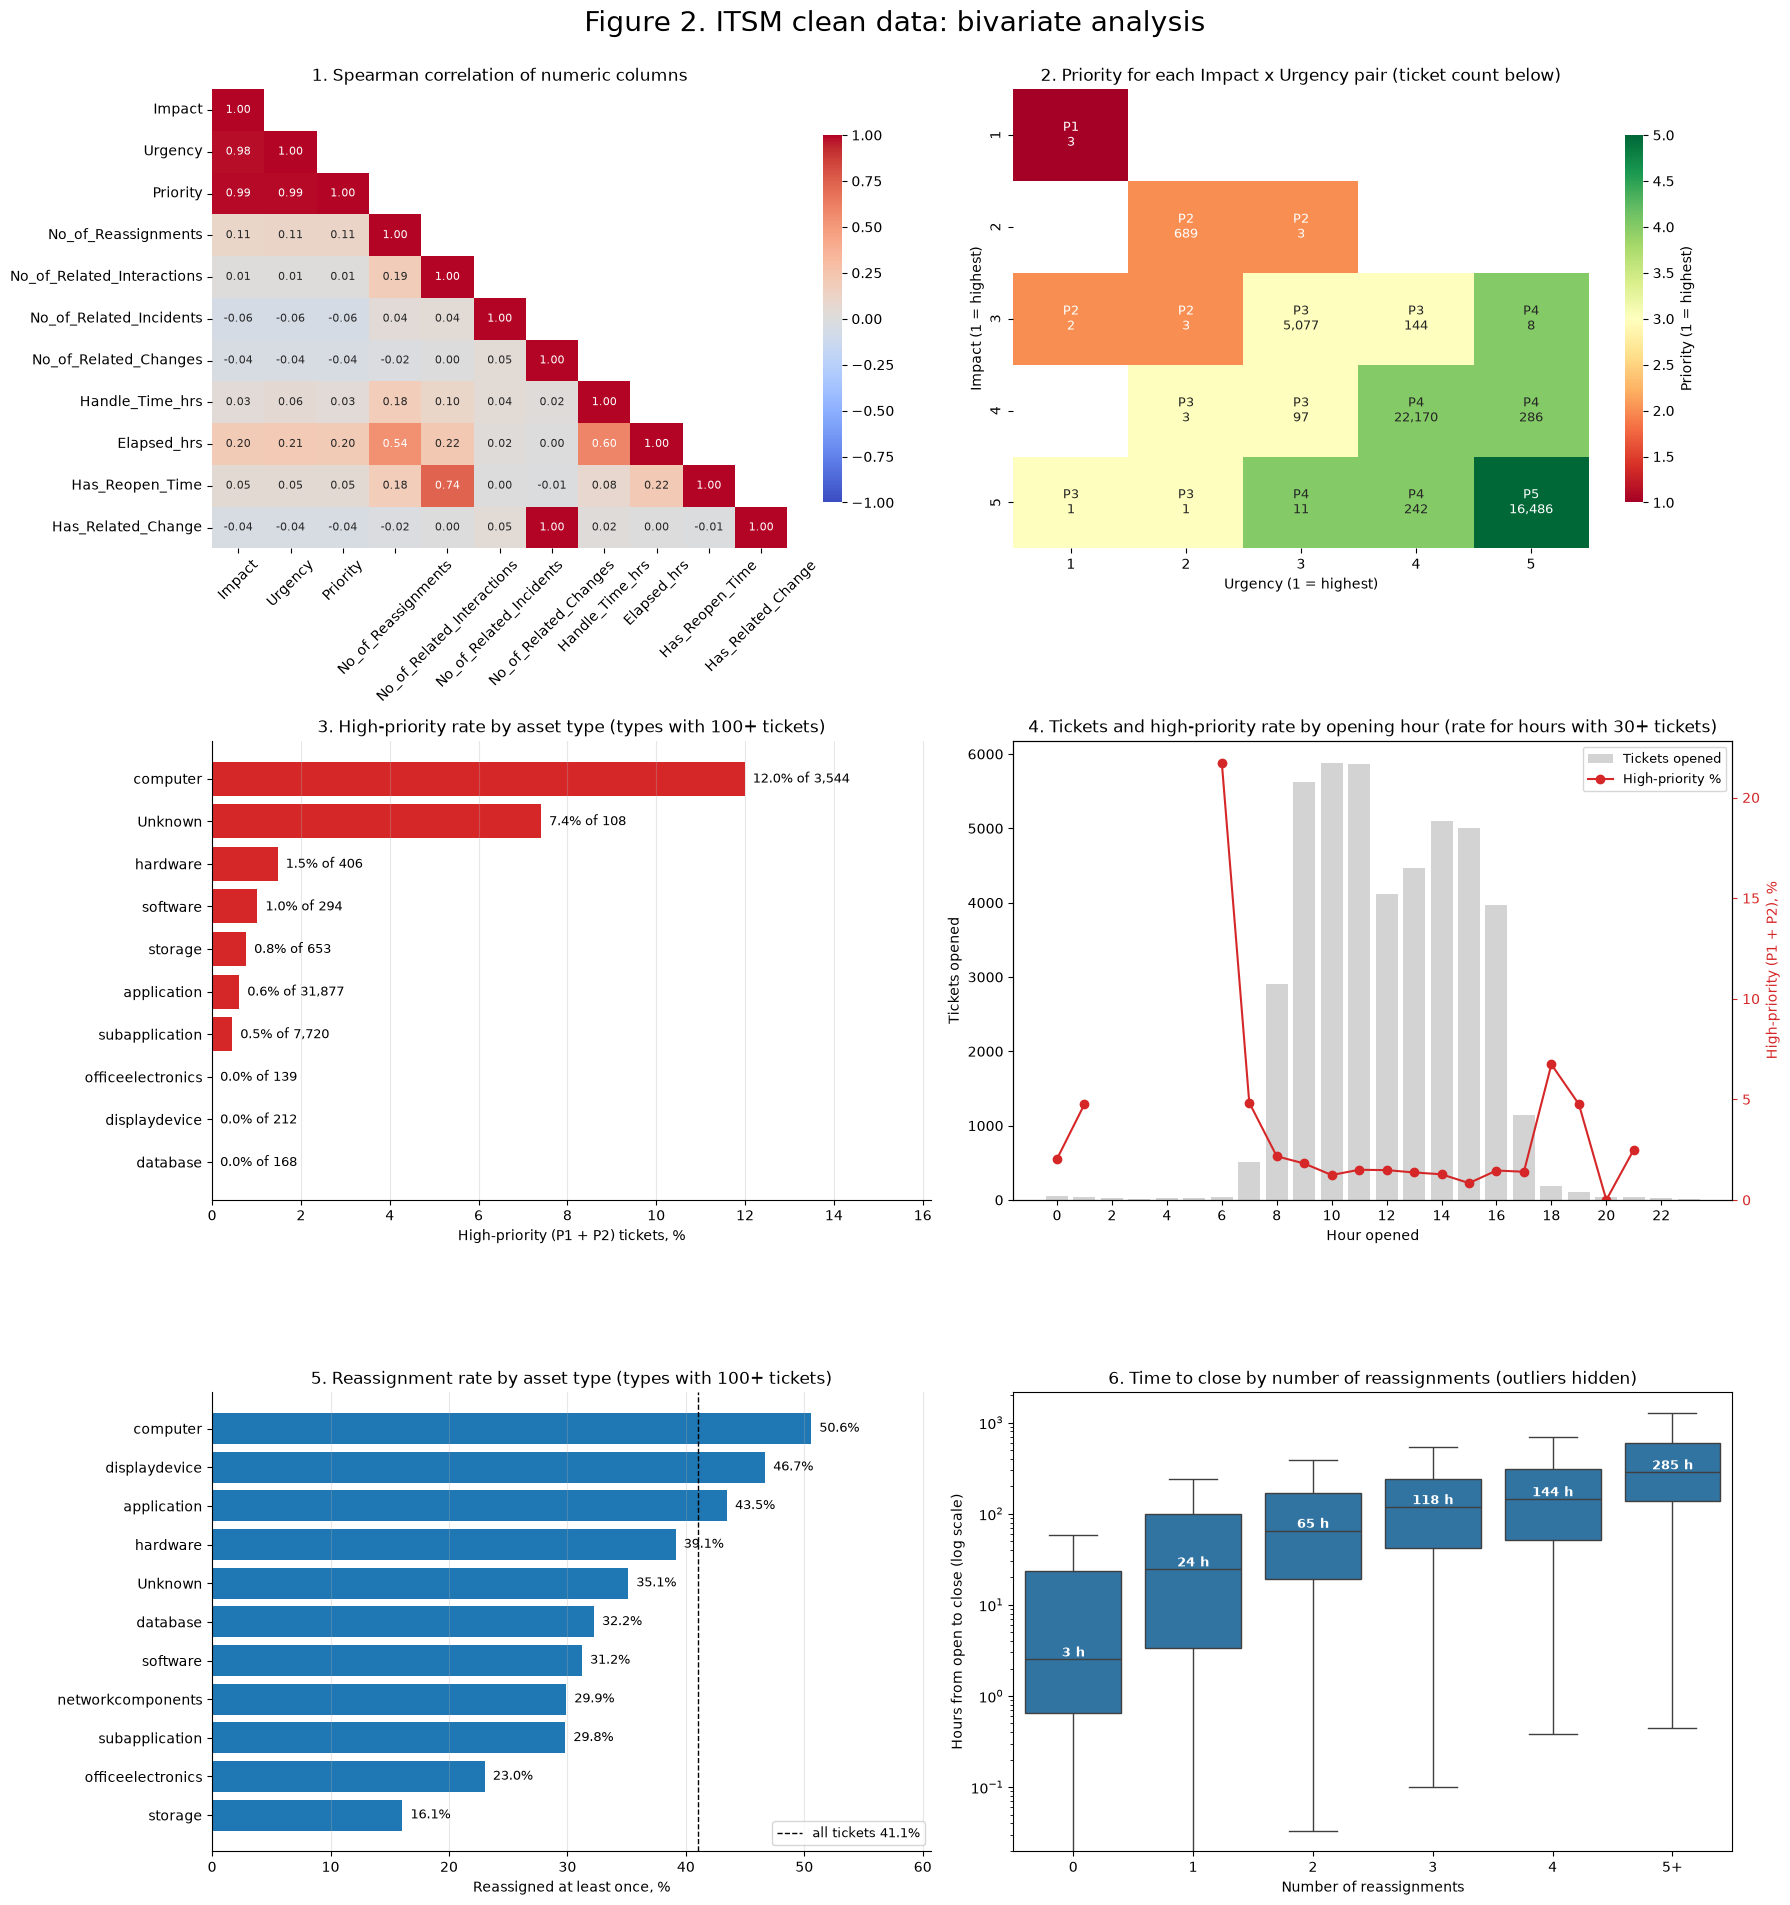

In [6]:
num_cols = ["Impact", "Urgency", "Priority", "No_of_Reassignments", "No_of_Related_Interactions",
            "No_of_Related_Incidents", "No_of_Related_Changes", "Handle_Time_hrs", "Elapsed_hrs",
            "Has_Reopen_Time", "Has_Related_Change"]

lab = df[df["Priority"].notna()].copy()                      # tickets with a priority label
lab["High"] = lab["Priority"].isin([1, 2]).astype(int)        # P1 or P2
lab["hour"] = lab["Open_Time"].dt.hour

fig, axes = plt.subplots(3, 2, figsize=(18, 19))
axes = axes.flatten()

# 1. Rank correlation of the numeric columns (Spearman: robust to skew and suits ordinal scales)
corr = df[num_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 8}, cbar_kws={"shrink": 0.8}, ax=axes[0])
axes[0].set_title("1. Spearman correlation of numeric columns")
axes[0].tick_params(axis="x", rotation=45)

# 2. Priority is a lookup of Impact and Urgency
lab["Impact"] = lab["Impact"].astype(int)
lookup = lab.pivot_table(index="Impact", columns="Urgency", values="Priority",
                         aggfunc=lambda s: s.mode().iloc[0])
counts = pd.crosstab(lab["Impact"], lab["Urgency"])
labels = lookup.map(lambda v: "" if pd.isna(v) else f"P{int(v)}") + "\n" + counts.reindex_like(lookup).map(lambda v: "" if pd.isna(v) or v == 0 else f"{int(v):,}")
sns.heatmap(lookup, annot=labels, fmt="", cmap="RdYlGn", vmin=1, vmax=5,
            cbar_kws={"label": "Priority (1 = highest)", "shrink": 0.8}, annot_kws={"size": 9}, ax=axes[1])
axes[1].set_title("2. Priority for each Impact x Urgency pair (ticket count below)")
axes[1].set_xlabel("Urgency (1 = highest)")
axes[1].set_ylabel("Impact (1 = highest)")

# 3. High-priority rate by asset type
g = lab.groupby("CI_Cat")["High"].agg(tickets="size", rate="mean")
g = g[g["tickets"] >= 100].sort_values("rate")
axes[2].barh(g.index, g["rate"] * 100, color="tab:red")
for k, (n, r) in enumerate(zip(g["tickets"], g["rate"])):
    axes[2].text(r * 100, k, f"  {r * 100:.1f}% of {n:,}", va="center", fontsize=9)
axes[2].set_xlim(0, g["rate"].max() * 100 * 1.35)
axes[2].set_xlabel("High-priority (P1 + P2) tickets, %")
axes[2].set_title("3. High-priority rate by asset type (types with 100+ tickets)")

# 4. Tickets and high-priority rate by opening hour
by_hour = lab.groupby("hour")["High"].agg(tickets="size", rate="mean").reindex(range(24), fill_value=0)
axes[3].bar(by_hour.index, by_hour["tickets"], color="lightgrey", label="Tickets opened")
axes[3].set_xlabel("Hour opened")
axes[3].set_ylabel("Tickets opened")
axes[3].set_xticks(range(0, 24, 2))
ax_r = axes[3].twinx()
ok = by_hour["tickets"] >= 30                                 # rate shown only for hours with 30+ tickets
ax_r.plot(by_hour.index, by_hour["rate"].where(ok) * 100, color="tab:red", marker="o", label="High-priority %")
ax_r.set_ylabel("High-priority (P1 + P2), %", color="tab:red")
ax_r.tick_params(axis="y", colors="tab:red")
ax_r.set_ylim(0, None)
h1, l1 = axes[3].get_legend_handles_labels(); h2, l2 = ax_r.get_legend_handles_labels()
axes[3].legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9)
axes[3].set_title("4. Tickets and high-priority rate by opening hour (rate for hours with 30+ tickets)")

# 5. Reassignment rate by asset type
r = df.dropna(subset=["No_of_Reassignments"]).assign(reassigned=lambda d: d["No_of_Reassignments"] >= 1)
by_cat = r.groupby("CI_Cat")["reassigned"].agg(tickets="size", rate="mean")
by_cat = by_cat[by_cat["tickets"] >= 100].sort_values("rate")
axes[4].barh(by_cat.index, by_cat["rate"] * 100, color="tab:blue")
for k, (n, v) in enumerate(zip(by_cat["tickets"], by_cat["rate"])):
    axes[4].text(v * 100, k, f"  {v * 100:.1f}%", va="center", fontsize=9)
overall = r["reassigned"].mean() * 100
axes[4].axvline(overall, color="black", linestyle="--", linewidth=1, label=f"all tickets {overall:.1f}%")
axes[4].set_xlim(0, by_cat["rate"].max() * 100 * 1.2)
axes[4].legend(loc="lower right", fontsize=9)
axes[4].set_xlabel("Reassigned at least once, %")
axes[4].set_title("5. Reassignment rate by asset type (types with 100+ tickets)")

# 6. Time to close by number of reassignments
r["n_reassign"] = r["No_of_Reassignments"].astype(int).clip(upper=5).map(lambda v: "5+" if v == 5 else str(v))
order = ["0", "1", "2", "3", "4", "5+"]
sns.boxplot(data=r, x="n_reassign", y="Elapsed_hrs", order=order, showfliers=False,
            color="tab:blue", ax=axes[5])
axes[5].set_yscale("log")
med = r.groupby("n_reassign")["Elapsed_hrs"].median().reindex(order)
for k, v in enumerate(med):
    axes[5].text(k, v, f"{v:.0f} h", ha="center", va="bottom", fontsize=9, color="white", fontweight="bold")
axes[5].set_xlabel("Number of reassignments")
axes[5].set_ylabel("Hours from open to close (log scale)")
axes[5].set_title("6. Time to close by number of reassignments (outliers hidden)")

for ax in axes[[2, 4]]:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)

fig.suptitle("Figure 2. ITSM clean data: bivariate analysis", fontsize=20, y=1.0)
fig.tight_layout()
plt.show()

<details>
<summary><b>Code notes, line by line</b></summary>

- `num_cols = [...]` : Numeric columns for the correlation heatmap.
- `lab = ...; lab["High"] = ...; lab["hour"] = ...` : Labelled tickets with the High flag and opening hour.
- `fig, axes = plt.subplots(3, 2, ...)` : Six charts.
- `Chart 1: corr(method="spearman"); np.triu(...); sns.heatmap(..., mask=mask)` : Rank correlations (robust to skew and suited to 1-to-5 scales); the mask hides the duplicate upper triangle.
- `Chart 2: pivot_table(..., aggfunc=lambda s: s.mode().iloc[0])` : The priority each Impact x Urgency pair maps to; crosstab adds the ticket count under each priority label.
- `Chart 3: groupby("CI_Cat")["High"].agg(tickets="size", rate="mean"); g[g["tickets"] >= 100]` : High-priority rate per asset type, only types with 100+ tickets so the rates are stable.
- `Chart 4: by_hour ... twinx() ... where(ok)` : Grey bars: tickets per opening hour; red line on a second axis: High rate, only for hours with 30+ tickets.
- `Chart 5: assign(reassigned=lambda d: d["No_of_Reassignments"] >= 1)` : Share reassigned at least once per asset type, with the overall rate as a dashed line.
- `Chart 6: clip(upper=5) ... sns.boxplot(..., showfliers=False); set_yscale("log")` : Hours to close by number of reassignments (5+ pooled), on a log scale with outlier dots hidden; medians written on the boxes.
- `for ax in axes[[2, 4]]: ...; fig.tight_layout(); plt.show()` : Styling and display.

</details>

**Why this analysis:** to find which columns are related to the targets (high priority, reassignment, delay), and which are related to each other in ways that would cause leakage. Scope: whole clean file; the models use the 167-day window. Each finding names the numbered panel of Figure 2 it is read from.

| Finding | Evidence | Action taken in the project |
|---|---|---|
| Impact, Urgency and Priority correlate at 0.98 to 0.99 | Figure 2, panel 1 | Impact and Urgency excluded from Track 1 features; Set A (with them) kept only as a contrast (`06_track1_models`) |
| Each Impact x Urgency pair maps to one priority: Priority is a lookup | Figure 2, panel 2 | Track 1 predicts High priority from asset and time fields, known when a ticket opens |
| Has_Related_Change equals No_of_Related_Changes (1.00) | Figure 2, panel 1 | The count excluded as a feature and as a target (`08_track4_rfc`) |
| Computer tickets are 12.0% High, against 0.5 to 1.5% for most asset types | Figure 2, panel 3 | CI_Cat and CI_Subcat used as features; the computer segment reported separately in Track 1's results |
| The High rate peaks early in the morning and in the evening, when few tickets arrive | Figure 2, panel 4 (red line against grey bars) | Hour and weekday added as features; rare hours pooled by the encoder (`05_split_features`) |
| Reassignment rates range from 16% (storage) to 51% (computer) | Figure 2, panel 5 | Asset fields used as Track 3 features; reassignment risk model adopted (`09_track3_triage`) |
| Median time to close rises from 3 hours (no reassignment) to 285 hours (five or more) | Figure 2, panel 6 (medians written on the boxes) | Used as the business case for Track 3, stated as an association, not a cause |
| Reassignments correlate with time to close (0.54) and with reopening (0.18) | Figure 2, panel 1 | Reassignment count kept out of Track 1's headline features because its timing is unconfirmed; tested only as a sensitivity run |

## 7. Tickets opened per month (dashed line: start of the close-date window)

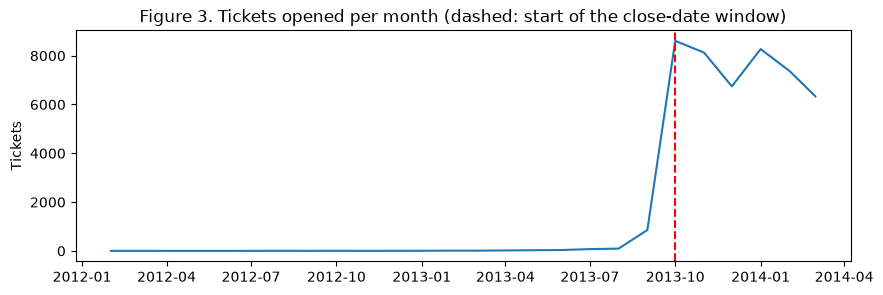

Table 7. Tickets opened per month, all months in the extract: summary
count      26.0
mean     1793.0
std      3260.0
min         0.0
25%         2.0
50%        10.0
75%       666.0
max      8606.0
dtype: float64


In [7]:
monthly = df.set_index("Open_Time").resample("MS").size()

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(monthly.index, monthly.values)
ax.axvline(pd.Timestamp("2013-10-01"), color="red", linestyle="--")
ax.set_title("Figure 3. Tickets opened per month (dashed: start of the close-date window)")
ax.set_ylabel("Tickets")
plt.show()
print("Table 7. Tickets opened per month, all months in the extract: summary")
print(monthly.describe().round(0))

<details>
<summary><b>Code notes, line by line</b></summary>

- `df.set_index("Open_Time").resample("MS").size()` : Tickets opened per calendar month (MS = month start labels).
- `ax.plot(...); ax.axvline("2013-10-01", ...)` : Line chart with a red dashed line at the start of the close-date window.
- `print(monthly.describe().round(0))` : Summary of the monthly counts.

</details>

## 8. Opened and closed per month: the extract is cut by close date

In [8]:
closed = df.set_index("Close_Time").resample("MS").size()
both = pd.DataFrame({"opened": monthly, "closed": closed}).fillna(0).astype(int)
print("Table 8. Tickets opened and closed per month, from July 2013")
print(both.loc["2013-07":])
print("Share opened Oct 2013 or later:", round((df["Open_Time"] >= "2013-10-01").mean() * 100, 1), "%")
print("Share closed Oct 2013 or later:", round((df["Close_Time"] >= "2013-10-01").mean() * 100, 1), "%")
print("Close_Time range:", df["Close_Time"].min().date(), "to", df["Close_Time"].max().date())

Table 8. Tickets opened and closed per month, from July 2013
            opened  closed
2013-07-01      73       0
2013-08-01      93       0
2013-09-01     857       0
2013-10-01    8606    8544
2013-11-01    8128    8052
2013-12-01    6743    7013
2014-01-01    8270    8210
2014-02-01    7377    7542
2014-03-01    6332    7245
Share opened Oct 2013 or later: 97.5 %
Share closed Oct 2013 or later: 100.0 %
Close_Time range: 2013-10-01 to 2014-03-31


<details>
<summary><b>Code notes, line by line</b></summary>

- `closed = df.set_index("Close_Time").resample("MS").size()` : Tickets closed per month.
- `both = pd.DataFrame({"opened": monthly, "closed": closed}).fillna(0)` : Opened and closed side by side; months with none become 0.
- `(df["Open_Time"] >= "2013-10-01").mean() vs Close_Time` : Share opened and share closed from October 2013: closed is 100%, which shows the extract is cut by close date.
- `df["Close_Time"].min() / max()` : The close-date range of the extract.

</details>

## 9. High-priority tickets per month

In [9]:
tot = lab.set_index("Open_Time").resample("MS").size()
hi = lab[lab["Priority"].isin([1, 2])].set_index("Open_Time").resample("MS").size()
print("Table 9. Labelled and High tickets per month, from September 2013")
print(pd.DataFrame({"labelled": tot, "high": hi}).fillna(0).astype(int).loc["2013-09":])

Table 9. Labelled and High tickets per month, from September 2013
            labelled  high
Open_Time                 
2013-09-01       831     1
2013-10-01      8344   178
2013-11-01      7901   133
2013-12-01      6551   130
2014-01-01      8049   100
2014-02-01      7154    79
2014-03-01      6113    79


<details>
<summary><b>Code notes, line by line</b></summary>

- `tot = lab...resample("MS").size()` : Labelled tickets per month.
- `hi = lab[lab["Priority"].isin([1, 2])]...` : High tickets per month.
- `pd.DataFrame({...}).loc["2013-09":]` : Both side by side from September 2013.

</details>

## 10. Survivorship: tickets opened before October 2013

In [10]:
pre = lab[lab["Open_Time"] < "2013-10-01"]
win = lab[lab["Open_Time"] >= "2013-10-01"]
print("Table 10. High rate before and from 1 October 2013 (labelled tickets)")
for name, part in [("Opened before Oct 2013", pre), ("Opened Oct 2013 onward", win)]:
    hi = part["Priority"].isin([1, 2]).sum()
    print(f"{name}: labelled {len(part)}, High {hi}, rate {hi / len(part) * 100:.2f}%")

Table 10. High rate before and from 1 October 2013 (labelled tickets)
Opened before Oct 2013: labelled 1114, High 1, rate 0.09%
Opened Oct 2013 onward: labelled 44112, High 699, rate 1.58%


<details>
<summary><b>Code notes, line by line</b></summary>

- `pre = lab[lab["Open_Time"] < "2013-10-01"]; win = ...` : Labelled tickets opened before and from October 2013.
- `hi = part["Priority"].isin([1, 2]).sum()` : High tickets in each group, printed with the rate: the backlog has almost none (survivorship).

</details>

### Findings: why the extract is not three years of data
1. The 1,150 tickets opened before October 2013 are the backlog still open on 1 October (Table 8: September 857, August 93, July 73; about 127 earlier). Figure 3 shows the same jump: opened counts are near zero for almost two years and then rise to 6,700 to 8,600 a month, and Table 7 shows half of all months in the extract have 10 or fewer tickets. These tickets are in the extract only because they closed inside the window (Table 8: nothing closed before October), so they are the slow tickets. That is survivorship bias: High-priority tickets get fixed fast and almost never appear there (Table 10: 1 High in 1,114 labelled, 0.09%, against 699 in 44,112, 1.58%, from October onward).
2. The close-date window covers 182 days (1 October 2013 to 31 March 2014); after the end is trimmed (section 12) there are 167 days of opened tickets. That is too short to fit or backtest a quarterly or annual model, so `07_track2_volume` fits the daily series and reports quarterly and annual volumes as planning estimates from a weekday run-rate validated on 4-week totals.
3. The High rate drifts down over the window (Table 9: 178 of 8,344, 2.13%, in October to 79 of 7,154, 1.10%, in February and 79 of 6,113, 1.29%, in March), so a threshold tuned on the early months will over-alert later.
4. With 79 High tickets in a single month (Table 9), one-month estimates are noisy.

## 11. Tickets not marked Closed

In [11]:
print("Table 11. Open and close dates of the tickets not marked Closed")
print(df.loc[df["Status"] != "Closed", ["Open_Time", "Close_Time"]].agg(["min", "max"]))

Table 11. Open and close dates of the tickets not marked Closed
              Open_Time          Close_Time
min 2013-10-08 13:10:00 2013-10-09 08:55:00
max 2013-10-28 15:03:00 2013-10-29 17:01:00


<details>
<summary><b>Code notes, line by line</b></summary>

- `df.loc[df["Status"] != "Closed", ["Open_Time", "Close_Time"]].agg(["min", "max"])` : Date range of the few tickets not marked Closed (dates only, no rows).

</details>

**Result.** The tickets not marked Closed (9, "Work in progress", `02_ingest_and_profile` Table 8a) were all opened and given a close time in October 2013 (Table 11). They are too few to matter, and Status is post-event in any case.

## 12. End of the window: is it right-censored?
Tickets opened in late March and still open on 31 March are missing from the extract. Weekly counts, p90 elapsed hours and the share of tickets over 72 hours show whether the last weeks are incomplete. The weekly High counts show the rate drifting, and the last line compares how fast High and other tickets close.

In [12]:
w = df[df["Open_Time"] >= "2013-10-01"].copy()
w["week"] = w["Open_Time"].dt.to_period("W")

tail = w.groupby("week").agg(
    opened=("Incident_ID", "size"),
    median_hrs=("Elapsed_hrs", "median"),
    p90_hrs=("Elapsed_hrs", lambda s: s.quantile(0.9)),
    share_over_72h=("Elapsed_hrs", lambda s: (s > 72).mean() * 100),
)
print("Table 12a. Last 10 weeks: tickets opened and hours to close")
print(tail.round(1).tail(10))

lab_w = w[w["Priority"].notna()].copy()
lab_w["high"] = lab_w["Priority"].isin([1, 2])
print("Table 12b. Last 10 weeks: labelled tickets (size) and High tickets (sum)")
print(lab_w.groupby("week")["high"].agg(["size", "sum"]).tail(10))
print("Table 12c. Median hours to close: High (True) against other tickets (False)")
print(lab_w.groupby("high")["Elapsed_hrs"].median().round(1))

Table 12a. Last 10 weeks: tickets opened and hours to close
                       opened  median_hrs  p90_hrs  share_over_72h
week                                                              
2014-01-27/2014-02-02    2098         7.7    216.1            24.0
2014-02-03/2014-02-09    2111        16.8    215.2            26.4
2014-02-10/2014-02-16    1749        18.0    220.8            27.4
2014-02-17/2014-02-23    1867        15.9    205.2            26.7
2014-02-24/2014-03-02    1656         7.6    190.9            23.8
2014-03-03/2014-03-09    1540        16.0    174.5            26.4
2014-03-10/2014-03-16    1627        11.0    170.6            24.2
2014-03-17/2014-03-23    1514         6.0    140.9            19.2
2014-03-24/2014-03-30    1421         3.9     71.4             9.9
2014-03-31/2014-04-06     217         1.8      4.8             0.0
Table 12b. Last 10 weeks: labelled tickets (size) and High tickets (sum)
                       size  sum
week                          

<details>
<summary><b>Code notes, line by line</b></summary>

- `w = df[df["Open_Time"] >= "2013-10-01"].copy(); w["week"] = ...to_period("W")` : Tickets from October, with their opening week.
- `tail = w.groupby("week").agg(opened=..., median_hrs=..., p90_hrs=..., share_over_72h=...)` : Per week: tickets opened, median and 90th-percentile hours to close, and % open longer than 72 hours.
- `print(tail.round(1).tail(10))` : The last 10 weeks, where censoring would show.
- `lab_w ... groupby("week")["high"].agg(["size", "sum"])` : Labelled and High tickets per week.
- `lab_w.groupby("high")["Elapsed_hrs"].median()` : Median hours to close for High and other tickets.

</details>

### Findings: the end of the window is right-censored
1. The share of tickets over 72 hours sits at 24 to 27% for seven weeks, then falls to 19.2%, 9.9% and 0.0% from the week of 17 March (Table 12a, last column); p90 hours fall the same way (from about 170 to 220 hours to 141, 71 and 5). Part of the drop at the very end is built in: a ticket opened on 29 or 30 March cannot exceed 72 hours when the data stops on 31 March. Median elapsed time is too unstable to use for this check (Table 12a: it swings between 7.6 and 18.0 hours in ordinary weeks); p90 and the share over 72 hours are steadier.
2. High tickets close much faster (Table 12c: median 3.8 hours against 18.1 for the rest), so tickets still open on 31 March are mostly slow, non-High tickets. That can inflate the late-window High rate (Table 12b): 23 of 1,371 labelled tickets (1.68%) in the week of 24 March, against 140 of 12,259 (1.14%) over the seven plateau weeks.

### Decision
End the modelling window before 17 March 2014.

## 13. Modelling window and Track 1 split sizes

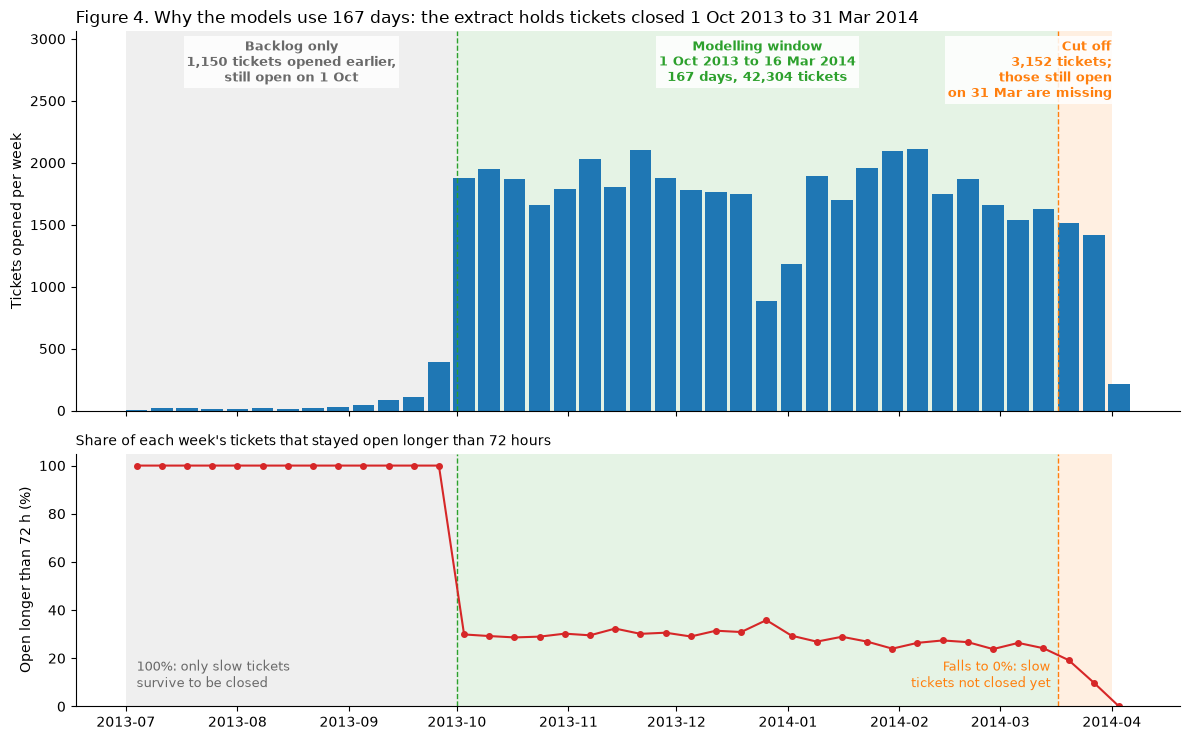

In [13]:
# Figure: why the modelling window is 1 October 2013 to 16 March 2014
start, cut = pd.Timestamp("2013-10-01"), pd.Timestamp("2014-03-17")
first, end = pd.Timestamp("2013-07-01"), df["Close_Time"].max().normalize() + pd.Timedelta(days=1)

v = df[df["Open_Time"] >= first].copy()
v["week"] = v["Open_Time"].dt.to_period("W-SUN").dt.start_time          # weeks start on Monday
v["over_72h"] = (v["Close_Time"] - v["Open_Time"]) > pd.Timedelta(hours=72)
wk = v.groupby("week").agg(tickets=("over_72h", "size"), over_72h=("over_72h", "mean"))

n_before = int((df["Open_Time"] < start).sum())
n_window = int(((df["Open_Time"] >= start) & (df["Open_Time"] < cut)).sum())
n_after = int((df["Open_Time"] >= cut).sum())
zones = [(first, start, "grey", f"Backlog only\n{n_before:,} tickets opened earlier,\nstill open on 1 Oct"),
         (start, cut, "tab:green", f"Modelling window\n1 Oct 2013 to 16 Mar 2014\n"
                                   f"{(cut - start).days} days, {n_window:,} tickets"),
         (cut, end, "tab:orange", f"Cut off\n{n_after:,} tickets;\nthose still open\non 31 Mar are missing")]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for ax in (ax1, ax2):
    for a, b, col, _ in zones:
        ax.axvspan(a, b, color=col, alpha=0.12, lw=0)
    for x, col in [(start, "tab:green"), (cut, "tab:orange")]:
        ax.axvline(x, color=col, linestyle="--", linewidth=1)
    ax.spines[["top", "right"]].set_visible(False)

ax1.bar(wk.index, wk["tickets"], width=6, align="edge", color="tab:blue")
ax1.set_ylim(0, wk["tickets"].max() * 1.45)
for a, b, col, text in zones:
    right = col == "tab:orange"                                      # the last zone is narrow: align its label right
    ax1.text(b if right else a + (b - a) / 2, wk["tickets"].max() * 1.42, text, ha="right" if right else "center",
             va="top", fontsize=9, color="dimgrey" if col == "grey" else col, fontweight="bold",
             bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
ax1.set_ylabel("Tickets opened per week")
ax1.set_title("Figure 4. Why the models use 167 days: the extract holds tickets closed 1 Oct 2013 to 31 Mar 2014", loc="left")

ax2.plot(wk.index + pd.Timedelta(days=3), wk["over_72h"] * 100, marker="o", markersize=4, color="tab:red")
ax2.set_ylim(0, 105)
ax2.set_ylabel("Open longer than 72 h (%)")
ax2.set_title("Share of each week's tickets that stayed open longer than 72 hours", loc="left", fontsize=10)
ax2.text(first + pd.Timedelta(days=3), 8, "100%: only slow tickets\nsurvive to be closed", fontsize=9, color="dimgrey")
ax2.text(cut - pd.Timedelta(days=2), 8, "Falls to 0%: slow\ntickets not closed yet", fontsize=9,
         color="tab:orange", ha="right")

fig.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
fig.savefig("../reports/figures/why_167_days.png", dpi=150, bbox_inches="tight")
plt.show()

<details>
<summary><b>Code notes, line by line</b></summary>

- `start, cut = ...; first, end = ...` : Window start (1 Oct 2013), cut-off (17 Mar 2014), plot start (July 2013) and the day after the last close date.
- `v["week"] = v["Open_Time"].dt.to_period("W-SUN").dt.start_time` : Monday-based week of each ticket.
- `v["over_72h"] = (Close_Time - Open_Time) > 72 hours` : Whether each ticket stayed open longer than 72 hours.
- `wk = v.groupby("week").agg(tickets=..., over_72h="mean")` : Tickets per week and the share over 72 hours.
- `n_before / n_window / n_after` : Ticket counts before, inside and after the modelling window, used in the zone labels.
- `zones = [(first, start, "grey", ...), (start, cut, "tab:green", ...), (cut, end, "tab:orange", ...)]` : The three shaded periods with their labels.
- `fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, ...)` : Two stacked panels sharing the date axis.
- `ax.axvspan(...); ax.axvline(...)` : Shades the zones and draws dashed lines at the window start and cut-off on both panels.
- `ax1.bar(wk.index, wk["tickets"], width=6, align="edge")` : Top panel: tickets opened per week.
- `ax1.text(... ha="right" if right ...)` : Zone labels; the narrow orange zone's label is right-aligned with a white box so it stays readable.
- `ax2.plot(wk.index + 3 days, wk["over_72h"] * 100, ...)` : Bottom panel: % of each week's tickets open longer than 72 hours, plotted mid-week.
- `ax2.text(...)` : Notes explaining the 100% (backlog) and 0% (not closed yet) ends.
- `os.makedirs(...); fig.savefig("../reports/figures/why_167_days.png", ...)` : Saves the figure for the report.

</details>

**Result.** Figure 4 puts sections 8 to 12 in one picture. The extract keeps tickets closed between 1 October 2013 and 31 March 2014. Before October (grey zone) only the slow backlog appears: the bottom panel shows 100% of those weeks' tickets open longer than 72 hours. After 16 March (orange zone) the slow tickets have not closed yet and the share falls to 0%. Between the two (green zone), weekly volume and the 72-hour share are steady, so the models use 1 October 2013 to 16 March 2014: 167 days and 42,304 tickets, with 3,152 opened from the cut-off left out (Table 13).

In [14]:

mw = df[(df["Open_Time"] >= start) & (df["Open_Time"] < cut)]
print("Table 13. Modelling window and Track 1 split sizes")
print("Modelling window rows:", len(mw), "| opened from cut-off:", int((df["Open_Time"] >= cut).sum()))

lab_m = mw[mw["Priority"].notna()]
for name, a, b in [("Train/tune Oct-Jan", "2013-10-01", "2014-02-01"),
                   ("Test Feb to 16 Mar", "2014-02-01", "2014-03-17")]:
    part = lab_m[(lab_m["Open_Time"] >= a) & (lab_m["Open_Time"] < b)]
    hi = part["Priority"].isin([1, 2]).sum()
    print(f"{name}: labelled {len(part)}, High {hi}, rate {hi / len(part) * 100:.2f}%")

Table 13. Modelling window and Track 1 split sizes
Modelling window rows: 42304 | opened from cut-off: 3152
Train/tune Oct-Jan: labelled 30845, High 541, rate 1.75%
Test Feb to 16 Mar: labelled 10229, High 115, rate 1.12%


<details>
<summary><b>Code notes, line by line</b></summary>

- `mw = df[(df["Open_Time"] >= start) & (df["Open_Time"] < cut)]` : The modelling window: opened 1 Oct 2013 to 16 Mar 2014.
- `print("Modelling window rows:", ...)` : Window size and the tickets left out after the cut-off.
- `lab_m = mw[mw["Priority"].notna()]` : Labelled tickets in the window.
- `for name, a, b in [("Train/tune Oct-Jan", ...), ("Test Feb to 16 Mar", ...)]` : Labelled tickets, High tickets and High rate in the Track 1 training and test periods.

</details>

## 14. Asset label review: similar CI_Subcat labels
Do some subcategories look like the same kind of asset recorded under two names? Each label is turned into word weights (TF-IDF) and every pair is compared by cosine similarity (1 = the same words). Pairs at 0.5 or above are then checked against the data: do the two labels sit under the same asset type (CI_Cat), and how much do their WBS codes overlap? Exact case duplicates were already merged in `03_cleaning`, section 7b. WBS codes are not shown.

In [15]:
labels = df["CI_Subcat"].value_counts().drop("Unknown", errors="ignore")
tfidf = TfidfVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b").fit_transform(labels.index)
sim = cosine_similarity(tfidf)
i, j = np.triu_indices(len(labels), k=1)
pairs = pd.DataFrame({"Label A": labels.index[i], "Label B": labels.index[j], "Similarity": sim[i, j]})
pairs = pairs[pairs["Similarity"] >= 0.5].sort_values("Similarity", ascending=False).reset_index(drop=True)

main_cat = df.groupby("CI_Subcat")["CI_Cat"].agg(lambda s: s.value_counts().index[0])
wbs = df.groupby("CI_Subcat")["WBS"].agg(set)
pairs["Tickets A"] = pairs["Label A"].map(labels)
pairs["Tickets B"] = pairs["Label B"].map(labels)
pairs["CI_Cat A"] = pairs["Label A"].map(main_cat)
pairs["CI_Cat B"] = pairs["Label B"].map(main_cat)
pairs["WBS overlap %"] = [round(len(wbs[a] & wbs[b]) / len(wbs[a] | wbs[b]) * 100, 1)
                          for a, b in zip(pairs["Label A"], pairs["Label B"])]
print(f"Table 14. CI_Subcat label pairs with cosine similarity 0.5 or more ({len(labels)} labels, "
      f"{len(i):,} pairs compared)")
display(pairs.round(2))

Table 14. CI_Subcat label pairs with cosine similarity 0.5 or more (63 labels, 1,953 pairs compared)


,Label A,Label B,Similarity,Tickets A,Tickets B,CI_Cat A,CI_Cat B,WBS overlap %
0,Desktop Application,Desktop,0.78,3876,423,application,computer,3.8
1,Database,Database Software,0.75,211,4,database,software,25.0
2,Server Based Application,Application Server,0.73,18811,1,application,applicationcomponent,0.0
3,Server Based Application,Client Based Application,0.69,18811,492,application,application,3.4
4,Server Based Application,Web Based Application,0.66,18811,15311,application,application,9.1
5,ESX Cluster,ESX Server,0.60,11,2,computer,computer,50.0
6,Web Based Application,Client Based Application,0.57,15311,492,application,application,3.2
7,zOS Cluster,zOS Server,0.57,17,4,computer,computer,50.0
8,NonStop Server,NonStop Harddisk,0.54,14,2,computer,computer,100.0
9,NonStop Server,NonStop Storage,0.54,14,1,computer,computer,0.0


<details>
<summary><b>Code notes, line by line</b></summary>

- `labels = df["CI_Subcat"].value_counts().drop("Unknown", errors="ignore")` : Each subcategory label with its ticket count; 'Unknown' is not a real label.
- `TfidfVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b").fit_transform(labels.index)` : Turns each label into word weights; the token pattern keeps one-letter words; words shared by many labels get less weight.
- `sim = cosine_similarity(tfidf)` : Similarity of every pair of labels: 1 = same words, 0 = no words in common.
- `i, j = np.triu_indices(len(labels), k=1)` : Each pair once (upper triangle, no label compared with itself).
- `pairs = ...; pairs[pairs["Similarity"] >= 0.5]` : Keeps pairs at 0.5 or above, most similar first.
- `main_cat = df.groupby("CI_Subcat")["CI_Cat"].agg(... value_counts().index[0])` : The usual asset type of each label.
- `wbs = df.groupby("CI_Subcat")["WBS"].agg(set)` : The set of WBS codes each label appears under.
- `pairs["Tickets A"], ["CI_Cat A"] ...` : Adds the ticket count and asset type of both labels.
- `"WBS overlap %" = len(a & b) / len(a | b) * 100` : Jaccard overlap of the two WBS sets: high overlap plus a similar name suggests a duplicate label.
- `display(pairs.round(2))` : Table 14 (labels and counts only, no codes).

</details>

**Result.** 13 of 1,953 label pairs reach 0.5 (Table 14). Most share a common word, not a meaning: Desktop Application and Desktop (0.78) sit under different asset types (application against computer) with 3.8% WBS overlap, and Server Based, Web Based and Client Based Application are distinct application types under one CI_Cat (WBS overlap 3 to 9%). The data supports one likely duplicate: zOS Server and zOS Systeem (Dutch for "system") share the asset type and all their WBS codes (6 tickets in all). NonStop Server and NonStop Harddisk also share their WBS codes but name different components. The review also shows Dutch labels mixed into an English taxonomy (zOS Systeem, Windows Server in extern beheer, and the Closure_Code "Kwaliteit van de output"). These are flagged for ABC Tech's CMDB review, not merged: they cover a handful of tickets that the encoder already pools, so no model depends on them.

## Decisions from this notebook
1. Modelling window: tickets opened on or after 2013-10-01 and before 2014-03-17 (42,304 rows; 41,074 have a priority label) (Figure 4, Table 13).
2. Track 1 split: train and tune on October to January (30,845 labelled tickets, 541 High); test 1 February to 16 March (10,229 labelled, 115 High) (Table 13). The test period is scored once for the headline result.
3. Track 2: models are fitted on the daily series (about 24 weeks of history); quarterly and annual volumes are planning estimates from a weekday run-rate (`07_track2_volume`, which also explains the 167 days).
4. Tickets opened before October 2013 are excluded from modelling (survivor backlog, Tables 8 and 10).
5. Outliers are not capped (Table 5, section 5).
6. Similar CI_Subcat labels are flagged for ABC Tech's CMDB review, not merged (Table 14, section 14); only exact case duplicates are merged (`03_cleaning`).